# Segundos contra vidas
### Lo que Medellín puede aprender de Bogotá y Malasia

**¿En qué vías de Medellín salvaría más vidas bajar la velocidad o separar a las motos, y cuántos segundos le costaría a cada conductor?**

Equipo *Segundos contra vidas* · Cristopher Corrales Boada, Josué Tamayo Uribe y Johan Hernando Lopez Londoño
Hackathon de Datos 2026 · ITM · Categoría interna · Análisis de datos · Transporte y movilidad

<details>
<summary><b>Cómo correr este notebook</b></summary>

1. Instalar las librerías: `pip install -r requirements.txt` (Python 3.13).
2. Correr las celdas en orden. Los datos se descargan solos desde sus fuentes oficiales (`src/fuentes.py`); nadie tiene que bajar nada a mano.
3. La primera vez tarda más, porque descarga las bases. Las tablas intermedias quedan en `data/processed/`.
4. El detalle de cada análisis está en los anexos: `notebooks/01` a `06`.
</details>

In [1]:
import os, sys
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src" / "fuentes.py").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError(f"No encontré el proyecto. El notebook está en: {Path.cwd()}")
    raiz = raiz.parent
os.chdir(raiz); sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
from src import graficas as G, historia as H
from src.velocidad import CORREDORES

NOMBRE = {cid: v[0] for cid, v in CORREDORES.items()}
RAPIDAS = ["AV_REGIONAL", "AUT_SUR", "AUT_NORTE"]
Path("figuras/final").mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre):
    """Guarda cada gráfica en figuras/final/ para las diapositivas."""
    fig.savefig(f"figuras/final/{nombre}.png", dpi=200, bbox_inches="tight")

H.revisar_requisitos();     # resultados de los anexos que usa la historia (notebooks 03, 05 y 06)

Resultados de los anexos: todo listo.


---
## Parte 0 · Con qué datos trabajamos

**Siete fuentes públicas que no se pueden unir entre sí. Para responder la pregunta, primero tuvimos que conectarlas.**

### 0.1 · Las siete fuentes y para qué usamos cada una

| Fuente | Quién la publica | Periodo | Qué trae | Para qué la usamos |
|---|---|---|---|---|
| **Incidentes del ITM** | Arango, Quiceno y Correa (2026), Mendeley Data | 2008 – ago 2025 | 702.540 incidentes con hora, gravedad y coordenadas | Los **incidentes graves** por corredor y hora: el efecto de la velocidad, la predicción y el Monte Carlo |
| **Víctimas en incidentes viales** | MEData · Secretaría de Movilidad | 2014 – sep 2021 | 235.843 víctimas con actor, edad, sexo y gravedad | **Quién muere:** el modelo de riesgo y el % de víctimas en moto por corredor |
| **Mortalidad** | Alcaldía de Medellín · Observatorio de Movilidad | 2019 – 2024 | 1.541 fallecidos con coordenadas | **Cuántos mueren y dónde:** la cifra oficial y la base de las vidas salvadas |
| **Incidentes viales con motos** | MEData | 2015 – 2021 | Una fila por vehículo | **El peso de la moto** y la letalidad según el diseño de la vía |
| **Velocidad y tiempo de viaje (Google Traffic)** | MEData · SIMM | 2017 – 2020, de 6 a 20 h | Velocidad de cada tramo, hora por hora | **Dónde se pasa de 50 km/h** y cuántos segundos costaría el tope |
| **Velocidad e intensidad vehicular** | MEData · SIMM | jul – ago 2020, 24 h | Velocidad y volumen en 303 sensores | **La velocidad de noche** y el trazado de los corredores |
| **Incidentes viales** | MEData | 2014 – 2020 | Incidentes por clase y gravedad | **Control:** comparar con la base del ITM |

**Evidencia externa** (el punto de comparación, verificado en cada fuente): Bogotá (límite de 50 km/h, 2018), Malasia (carril exclusivo de motos, 1995), Elvik (2009) y Nilsson (relación entre velocidad y siniestros) y la FHWA de Estados Unidos (límite variable). Detalle en `docs/referentes.md`.

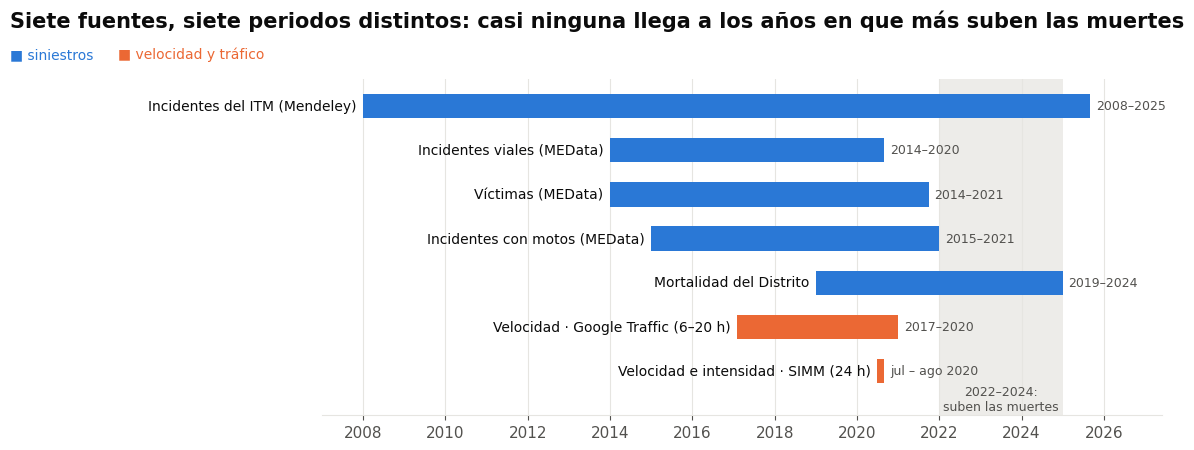

In [2]:
fig = G.linea_tiempo_fuentes(); guardar(fig, "00_linea_tiempo_fuentes")

### 0.2 · Las fuentes no hablan entre sí
Ninguna fuente comparte un identificador con otra, y los tramos de velocidad no traen coordenadas: algunos terminan en sitios como "Tugo" o "CTI". **Construimos nuestro propio mapa de los 12 corredores** con los sensores del SIMM, cortado a los tramos de Google Traffic, y ubicamos cada incidente, víctima y muerto en el corredor que queda a menos de 50 m. Así, por primera vez, la velocidad y los siniestros de un mismo corredor se pueden comparar.

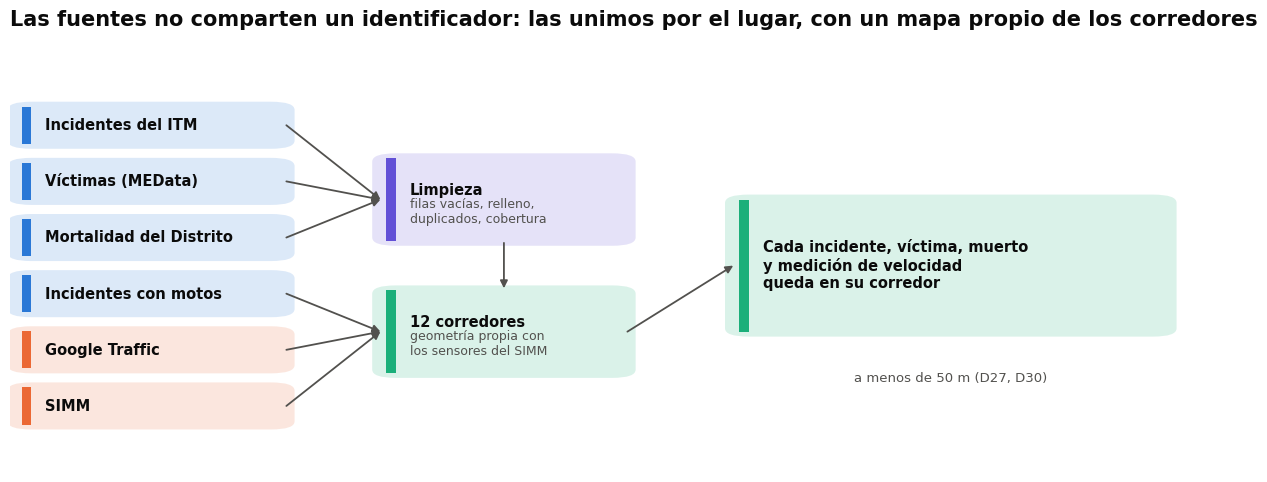

In [3]:
fig = G.diagrama_datos(); guardar(fig, "00_diagrama_datos")

> **Cómo sabemos que funciona:** 55.832 incidentes graves quedan en algún corredor. En 10 de los 11 corredores con número propio, entre el 64% y el 94% de esos incidentes nombran su vía en la dirección. Y el resultado casi no cambia si el radio es de 30 o de 100 m.

### 0.3 · Lo que encontramos al revisar los datos, y cómo lo resolvimos

| Lo que encontramos | Qué habría pasado si no lo corregíamos | Qué hicimos |
|---|---|---|
| El archivo de víctimas tiene 1.048.317 filas, pero 812.474 están vacías | Contar 4 veces más víctimas | Quedarnos con las filas reales |
| La base del ITM registra entre el 52% y el 91% de los muertos oficiales | Un falso "pico" de muertes en 2022 | Contar los muertos con la cifra del Distrito |
| Desde 2023 casi no se registran los choques de solo daños | Una falsa caída de los incidentes | Usar solo incidentes graves (0.4) |
| En 2024 los incidentes con coordenadas bajan de 94% a 86% | Una falsa caída de 22% en los corredores | Corregir por la cobertura de cada mes |
| La base de motos tiene una fila por vehículo | Contar dos veces el mismo choque | Quitar los registros repetidos |
| Direcciones de relleno ("Calle 999", "N/D") | Incidentes ubicados en lugares falsos | Tratarlas como datos faltantes |

### 0.4 · Por qué contamos incidentes graves (heridos y muertos)
**Desde 2023 casi no se registran los choques de solo daños. Si los contáramos, parecería que Medellín mejoró, y no es así.**

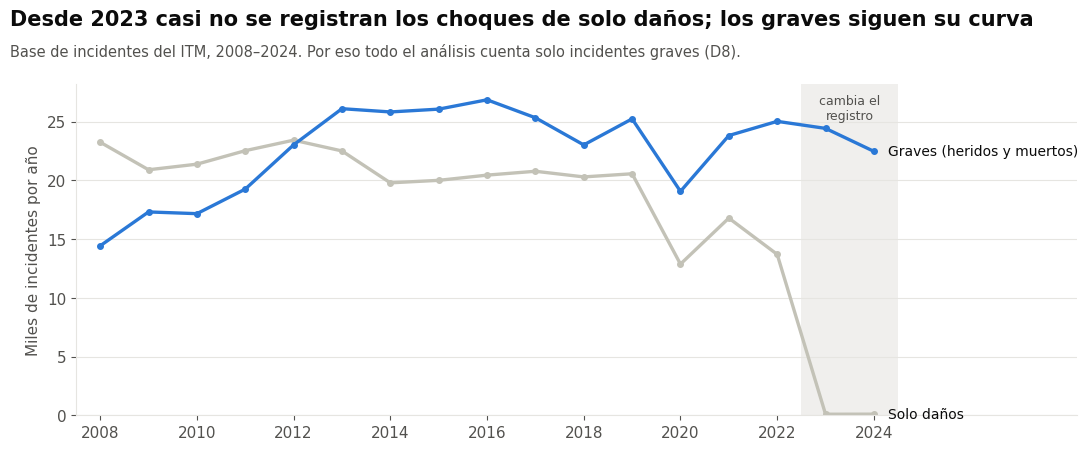

In [4]:
inc = H.incidentes()
fig = G.graves_contra_danos(H.graves_y_danos(inc)); guardar(fig, "00_graves_contra_danos")

- La caída de los solo daños es un cambio en cómo se registran, no menos choques.
- Los graves se registran igual todos los años, y son los que importan: en cada uno hay alguien herido o muerto.
- Además son muchos más que los muertos (unos 120 por cada muerto), así que dan resultados firmes donde los muertos solos serían muy pocos.

> **Cómo lo sabemos:** de los 702.540 incidentes del ITM, 403.135 son graves. Comparamos su evolución año por año con la de los solo daños.

---
## El camino del análisis
**Seis análisis: cada uno responde una pregunta y le pasa su resultado al siguiente.**

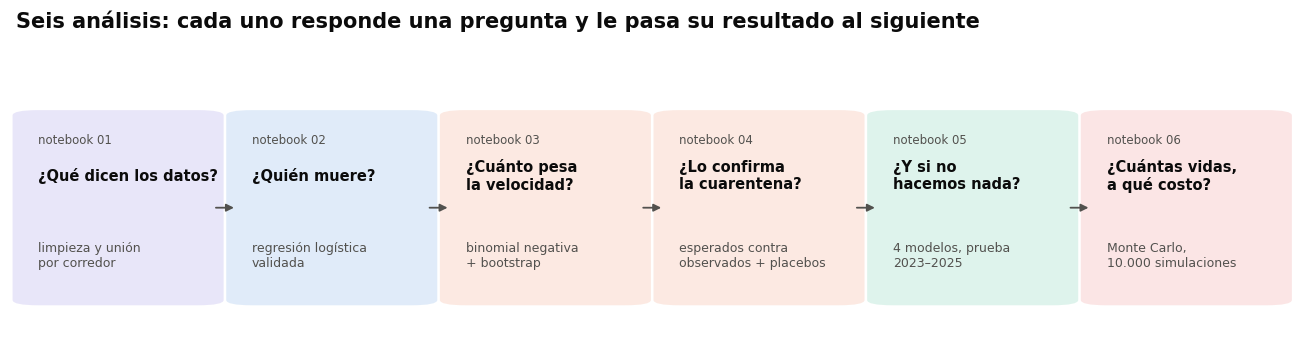

In [5]:
fig = G.camino_analisis(); guardar(fig, "00_camino_analisis")

| # | Pregunta | Qué hicimos | Resultado que pasa a la historia |
|---|---|---|---|
| 01 | ¿Qué dicen y qué no dicen los datos? | Revisamos, limpiamos y unimos las 7 fuentes por corredor | 294 de 1.541 muertos en 12 corredores; 3 de ellos concentran la mitad |
| 02 | ¿Quién muere y por qué? | Comparamos víctimas parecidas que solo se diferencian en una cosa | Ser peatón multiplica el riesgo de morir por 3,4; tener 60 años o más, por 5,7 |
| 03 | ¿Cuánto pesa la velocidad en Medellín? | Comparamos el mismo corredor en horas más rápidas y más lentas | La evidencia directa es débil: por eso simulamos con un rango |
| 04 | ¿Lo confirma un experimento real? | Usamos la cuarentena, cuando la ciudad fue 30% más rápida, y la comparamos con 5 años normales | Va en la dirección esperada, pero no es prueba |
| 05 | ¿Qué pasa si no hacemos nada? | Predijimos 2023–2025 sin mostrarle esos años al modelo | Unos 10 incidentes graves al día en 12 vías |
| 06 | ¿Cuántas vidas, a qué costo? | Repetimos el cálculo 10.000 veces con todo lo que no sabemos con exactitud | 5,7 vidas al año con las dos medidas; 57 s por viaje en la Regional |

*Lo que sigue es la historia que cuentan estos seis análisis juntos.*

---
## La respuesta corta

| | |
|---|---|
| **3 vías** | La Regional, la Autopista Sur y la Autopista Norte concentran casi la mitad de los muertos de los 12 corredores principales. |
| **5,7 vidas al año** | (entre 4,4 y 7,1) y **372 incidentes graves menos** si en esas 3 vías se separa a las motos y se baja la velocidad donde se pasa de 50: una de cada cuatro muertes y uno de cada cuatro incidentes graves de esas vías. |
| **57 segundos** | por viaje es lo que cuesta el tope de 50 km/h en la Regional, la vía donde más rinde. El carril de motos no cuesta segundos. |

---
## Acto I · El problema

### 1 · Cada 28 horas muere alguien
**En 2024 murieron 313 personas en las vías de Medellín, una cada 28 horas. Es la cifra más alta en al menos 11 años.**

2019 en las dos fuentes (MEData, Distrito): (247, 251)


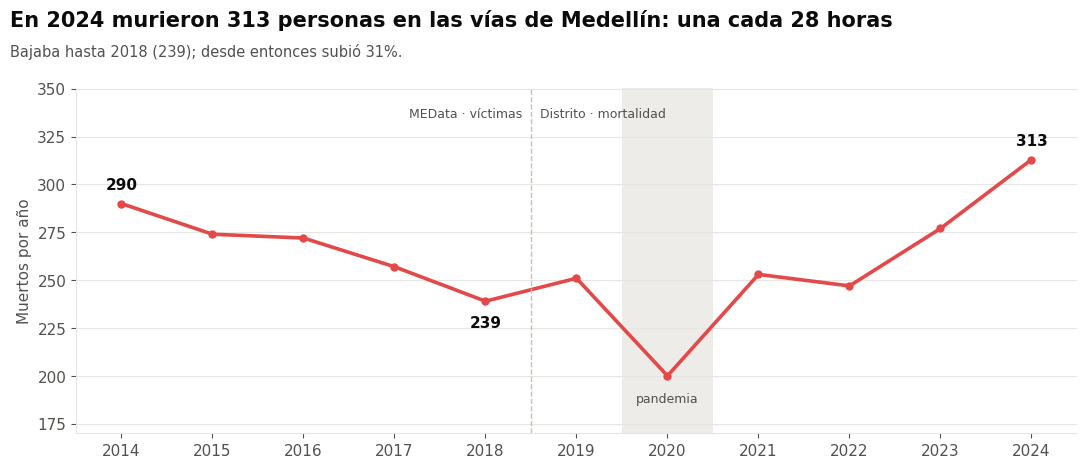

In [6]:
vic, mor = H.victimas(), H.mortalidad()
serie = H.muertes_por_anio(vic, mor)
fig = G.muertes_por_anio(serie); guardar(fig, "01_muertes_por_anio")
print("2019 en las dos fuentes (MEData, Distrito):", serie.attrs["empalme_2019"])

- **Medellín estaba mejorando:** entre 2014 y 2018 las muertes bajaron 18%, de 290 a 239.
- **Desde entonces la curva se devolvió:** +31% hasta 2024. Y 2020 no cuenta como mejora: la ciudad estuvo encerrada.
- **Los muertos son la punta del problema:** por cada persona que muere, unas 120 quedan heridas. Son unas 30.000 víctimas al año, 80 por día.

> **Cómo lo sabemos:** unimos dos fuentes oficiales: las víctimas de MEData hasta 2018 y el Distrito desde 2019. En 2019, el año en que se cruzan, coinciden, así que la serie se puede leer como una sola.

→ *¿Las muertes caen al azar, o tienen un patrón?*

### 2 · No es mala suerte: es un patrón
**Las muertes no están repartidas al azar: se concentran en pocos lugares, a ciertas horas y en ciertas personas. Y lo que tiene patrón se puede prevenir.**

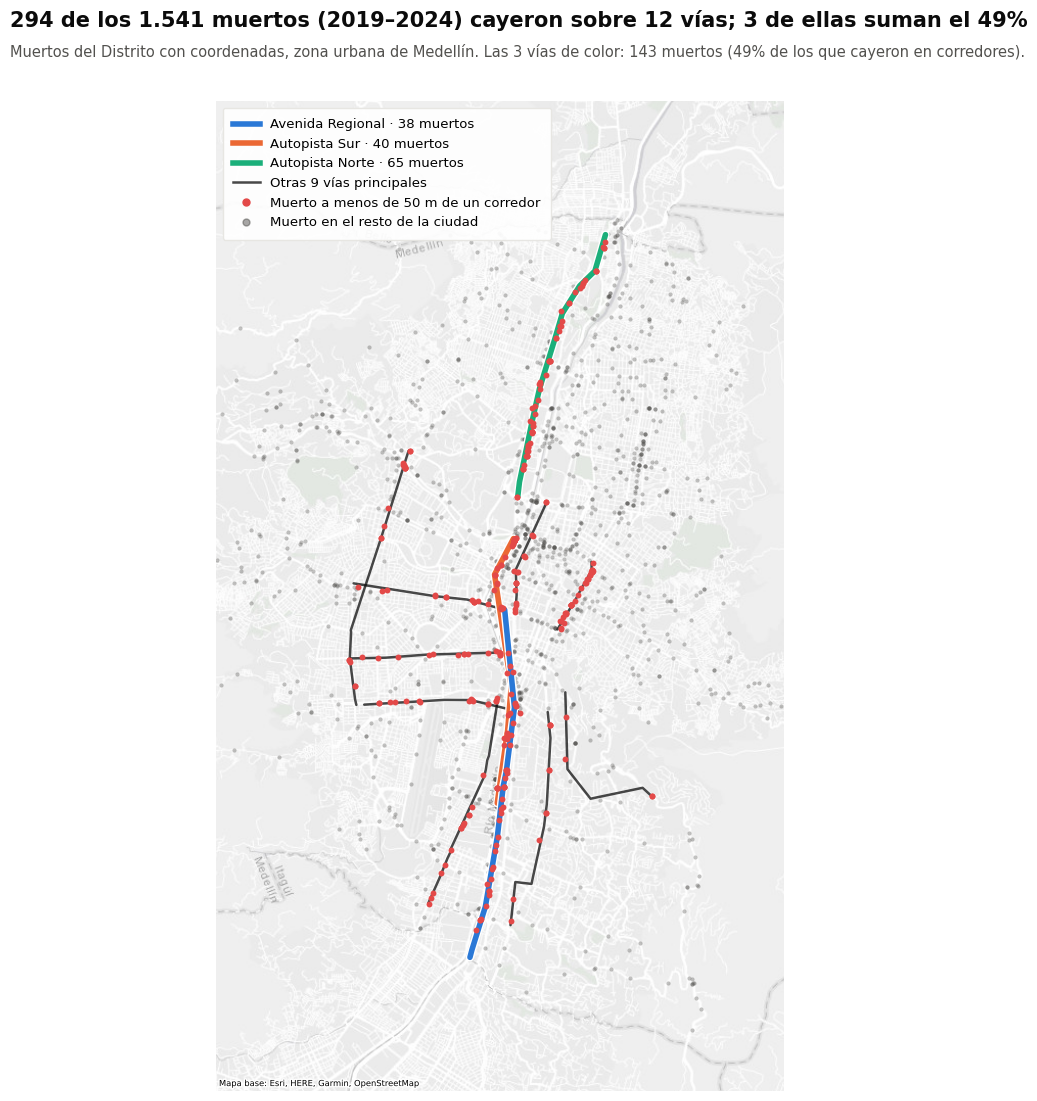

In [7]:
fig = G.mapa_corredores(H.mortalidad_corredor(), H.catalogo(), NOMBRE, destacados=RAPIDAS)
guardar(fig, "02_mapa_corredores")

Tres pistas, y cada una abre una parte de la historia:
- **Dónde:** el 19% de los muertos cae sobre solo 12 corredores, y tres de ellos (en azul) concentran casi la mitad → *Acto III*.
- **Quiénes:** 9 de cada 10 muertos son peatones o motociclistas → *Acto II*.
- **Cuándo:** en los corredores, la mitad de los muertos es de noche, aunque de noche ocurre solo uno de cada cuatro incidentes graves → *Cierre*.

> **Cómo lo sabemos:** cada muerto del Distrito tiene coordenadas; lo asignamos al corredor que queda a menos de 50 m de nuestro mapa (Parte 0.2).

→ *¿Quiénes son esos 313?*

---
## Acto II · Quién muere y por qué

### 3 · Los muertos tienen dos caras
**9 de cada 10 muertos son peatones o motociclistas. Pero no mueren por la misma razón.**

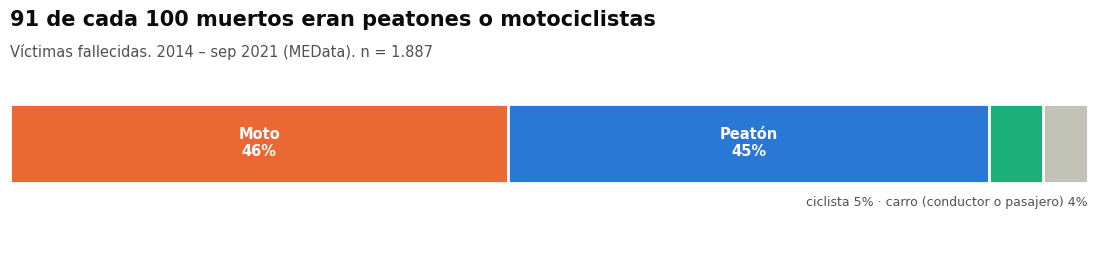

In [8]:
m = H.victimas_modelo()
actores = H.por_actor(m)
fig = G.muertos_por_actor(actores); guardar(fig, "03a_muertos_por_actor")

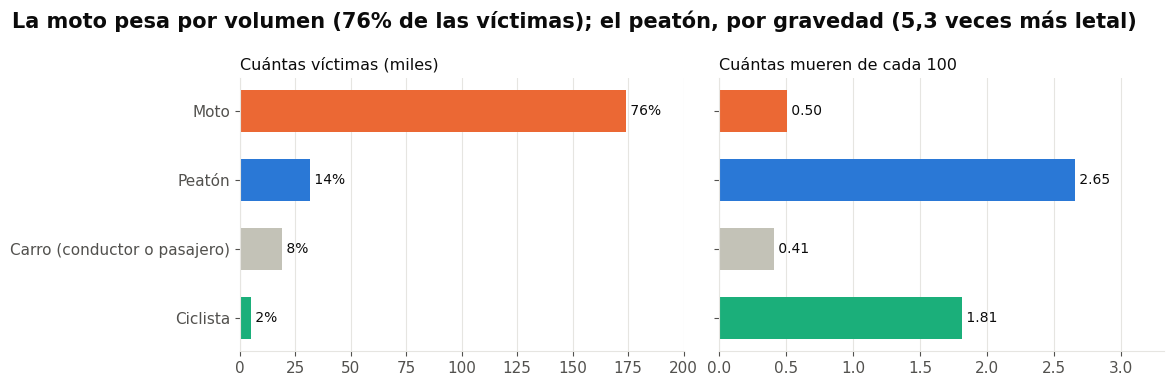

In [9]:
fig = G.volumen_y_letalidad(actores); guardar(fig, "03b_volumen_y_letalidad")

- **La moto pesa por volumen:** son 3 de cada 4 víctimas, y hay una moto en 8 de cada 10 incidentes graves.
- **El peatón pesa por gravedad:** de cada 100 peatones víctimas mueren unos 2,8; de cada 100 motociclistas, 0,5.
- Son dos problemas distintos mezclados en una misma cifra.

> **Cómo lo sabemos:** cada una de las víctimas trae su condición (peatón, motociclista, parrillero, ciclista, conductor o pasajero). La presencia de la moto en los incidentes graves sale de otra fuente, la base de motos, contando cada choque una sola vez.

→ *¿Por qué el peatón muere tanto más?*

### 4 · El mismo choque no pesa igual para todos
**Ser peatón multiplica por 3,4 el riesgo de morir; tener 60 años o más, por 5,7; la madrugada, por 3,2. Y los factores se suman.**

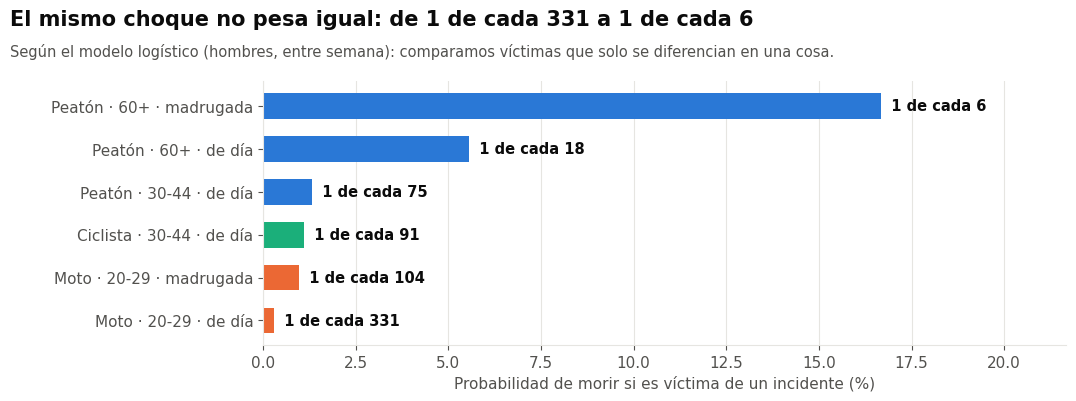

In [10]:
from src.modelos import modelo_logistico, probabilidad_perfiles
modelo = modelo_logistico(m)
fig = G.perfiles(probabilidad_perfiles(modelo)); guardar(fig, "04_perfiles")

- Sin carrocería, el cuerpo recibe todo el impacto.
- Según quién recibe el choque y a qué hora, el riesgo de morir cambia unas 50 veces.
- En los datos, sin modelo: de los peatones de 60 años o más atropellados de madrugada, murió 1 de cada 7 (33 de 236).

> **Cómo lo sabemos:** una regresión logística con actor, edad, sexo, hora, día y año, que compara víctimas que solo se diferencian en una cosa. **La probamos con 2020–2021, años que no vio:** predijo 353 muertos y hubo 357 (AUC 0,76).

<details><summary>Nota técnica</summary>

Errores agrupados por incidente (varias víctimas del mismo choque no son independientes). Odds ratios completos, calibración y validación en el anexo 02.
</details>

→ *Si al peatón lo protegemos mejor, ¿qué pasa con la moto?*

### 5 · Medellín aprendió a proteger al peatón; con la moto, no tanto
**Antes de la pandemia, los peatones muertos bajaron cerca de una cuarta parte; los motociclistas casi no cambiaron, y desde 2016 son tantos o más que los peatones.**

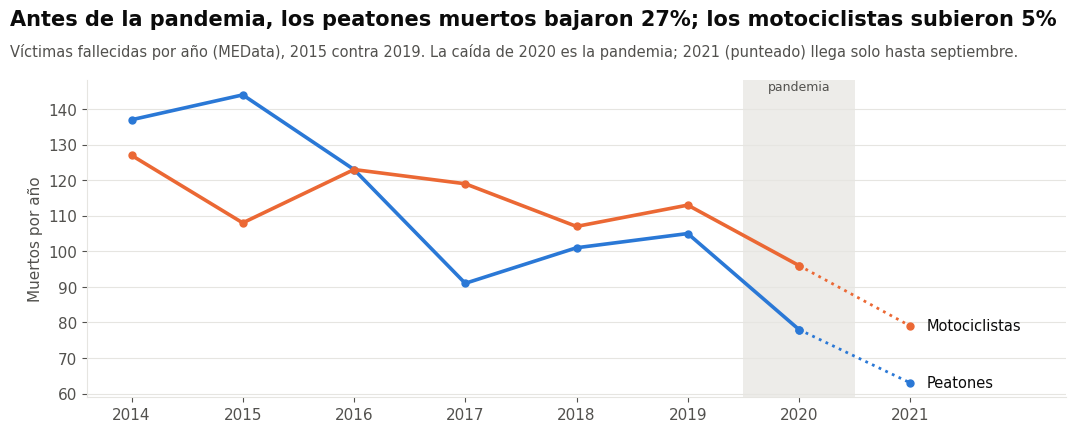

In [11]:
fig = G.peaton_contra_moto(H.muertos_peaton_moto(m)); guardar(fig, "05_peaton_contra_moto")

- **Entre 2015 y 2019**, los años normales que cubre el archivo, los peatones muertos bajaron y los motociclistas se quedaron casi iguales.
- **La caída de 2020 no es una mejora:** es la pandemia, con la ciudad encerrada. Y 2021 llega solo hasta septiembre, así que tampoco se puede comparar.
- No sabemos por qué bajaron los peatones muertos: no lo atribuimos a ninguna política.

### Dos problemas, dos medidas

| Problema | Por qué muere | Medida | Quién lo probó | Resultado |
|---|---|---|---|---|
| **El peatón** (y el ciclista y los mayores) | Por gravedad: el impacto llega al cuerpo sin protección | **Bajar la velocidad** | Bogotá (2018) | Muertes entre −22% y −37% en las avenidas intervenidas |
| **La moto** | Por volumen: está en 8 de cada 10 incidentes graves | **Separarla del tráfico** | Malasia (carril exclusivo) | Entre 25% y 34% menos accidentes de moto |

*Medellín no tiene que inventar nada: tiene que decidir dónde aplicar lo que ya funcionó.*

→ *Pero, ¿cuánto pesa la velocidad en Medellín, y dónde se va rápido?*

---
## Acto III · La velocidad actúa dos veces
*La velocidad hace que haya más choques, y hace que cada choque mate más.*

### 6 · Donde se va más rápido, el choque mata más
**Un choque en moto en un paso elevado mata más del doble que uno en una intersección.**

Fuera de la gráfica (no son vías): Lote o Predio (27.524 incidentes graves)


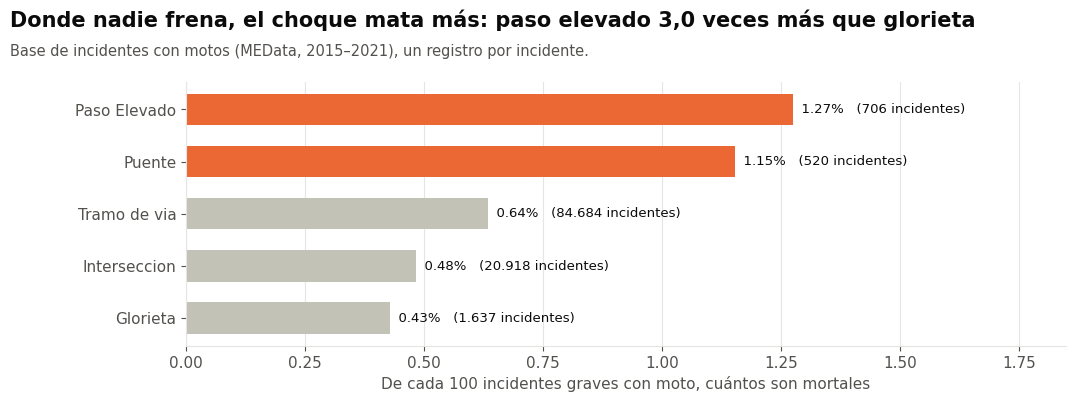

In [12]:
fig = G.letalidad_diseno(H.letalidad_diseno()); guardar(fig, "06_letalidad_diseno")

- En un paso elevado nadie frena; en una intersección, todos. El diseño de la vía es un reflejo de la velocidad.
- **"Lote o predio" queda fuera de la gráfica:** son incidentes dentro de un lote o un predio (parqueaderos, entradas de vehículos), no en la vía, así que no es un diseño de vía. Tiene muchos incidentes y casi ninguno mortal, como se espera a baja velocidad.

> **Cómo lo sabemos:** la base de motos trae el diseño de la vía de cada choque, y contamos cada choque una sola vez. Es una prueba independiente: esa base no tiene ningún dato de velocidad.

→ *¿Entonces hay que bajar la velocidad en toda la ciudad?*

### 7 · Medellín tiene dos velocidades
**En 9 de los 12 corredores la congestión ya obliga a ir despacio. Solo en 3 vías rápidas se pasa de 50 km/h, y no solo de día.**

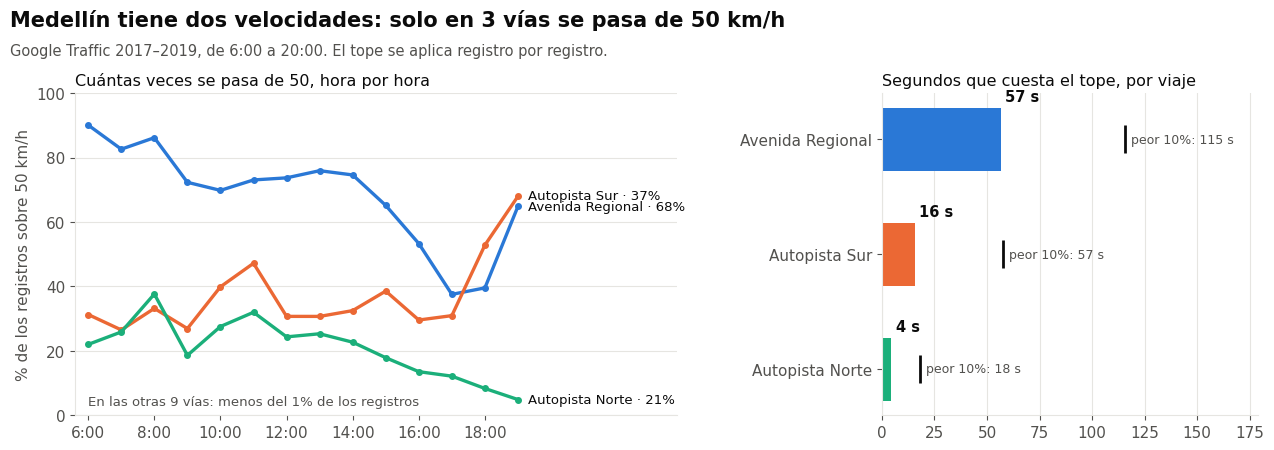

In [13]:
fig = G.dos_velocidades(H.dos_velocidades(), NOMBRE, RAPIDAS); guardar(fig, "07_dos_velocidades")

- En la Regional se pasa de 50 todo el día; en la congestión nadie llega a 50, así que ahí el tope no cuesta nada.
- **De noche el exceso no se apaga:** entre las 0 y las 4 a. m. sigue pasando de 50 entre el 15% y el 28% del tráfico de esas vías, y la velocidad de noche es la misma que de día.

> **Cómo lo sabemos:** aplicamos el tope registro por registro a las mediciones de Google Traffic, no al promedio, que esconde las horas rápidas. La noche sale del SIMM, usando solo cuánto cambia frente al día, porque las dos fuentes miden distinto.

**Decisión:** el tope se evalúa en la Regional, la Autopista Sur y la Autopista Norte, a cualquier hora.

→ *¿Y cuánto más choque hay cuando se va más rápido?*

### 8 · Primera vez: más velocidad, más choques
**En Medellín la evidencia directa es débil: según cómo se mida, el efecto de la velocidad va de nada a la mitad de lo que dice la literatura. Por eso no apostamos a un solo número: simulamos con un rango.**

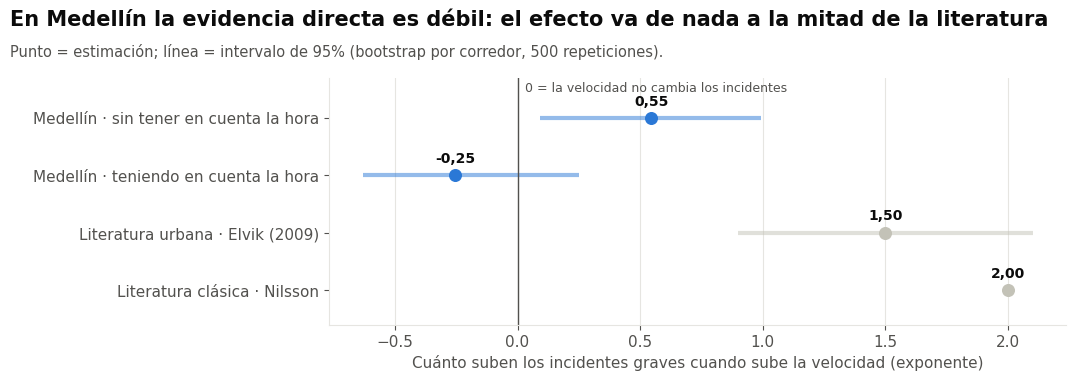

In [14]:
fig = G.exponente(*H.exponentes()); guardar(fig, "08_exponente")

- Comparando el mismo corredor en horas más rápidas y más lentas, +10% de velocidad trae unos +5% de incidentes graves. La literatura clásica diría +21%.
- Si además se tiene en cuenta la hora, el efecto desaparece: dentro de un corredor, la velocidad cambia sobre todo por la congestión, y estos datos no pueden separar las dos cosas.

> **Cómo lo sabemos:** un modelo de conteo (binomial negativa) sobre 8.791 incidentes graves, con el volumen de tráfico como exposición. Lo pusimos a prueba de tres formas: 500 repeticiones con corredores sorteados, quitando un corredor a la vez y cambiando el radio de 30 a 100 m. El resultado no depende de ninguna de las tres.

→ *¿Y cada choque, mata más cuando se va más rápido?*

### 9 · Segunda vez: la ciudad hizo el experimento
**En la cuarentena Medellín fue un 30% más rápida, y murió más gente de la esperada. Pero en años normales ya pasó algo parecido: va en la dirección esperada, sin ser prueba.**

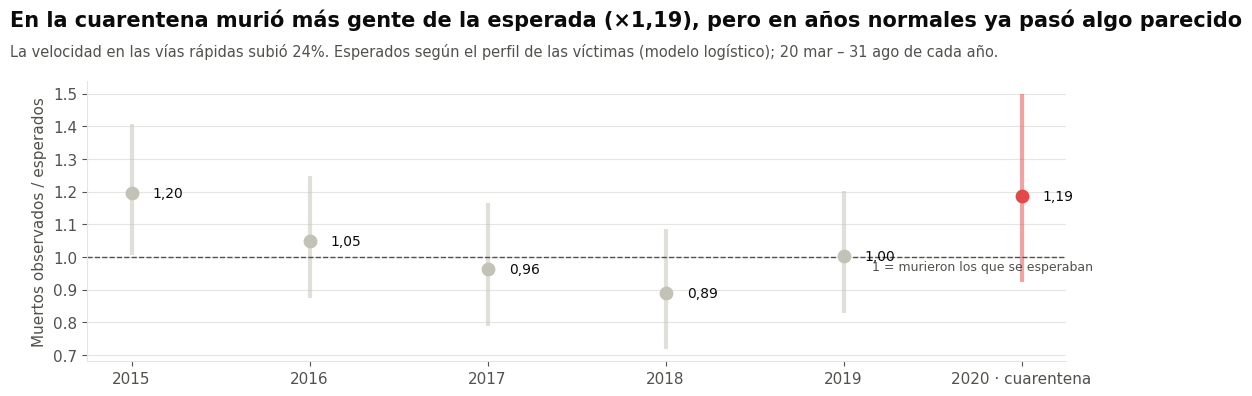

In [15]:
from src.modelos import backtest
bt = backtest(m)
fig = G.cuarentena(bt); guardar(fig, "09_cuarentena")

- Con calles vacías, las vías rápidas pasaron de unos 45 a 58 km/h.
- El efecto de la velocidad sobre la letalidad que implica este resultado (0,64) es compatible con el de la literatura para vías urbanas (cerca de 1,1).
- El total de muertos cayó, porque hubo menos viajes: cuánta gente está expuesta pesa tanto como la velocidad. Es el argumento del carril de motos.

> **Cómo lo sabemos:** con el modelo del paso 4 calculamos cuántos muertos se esperaban en la cuarentena según el perfil de las víctimas, y los comparamos con los que hubo. Hicimos la misma prueba en 5 años normales para ver si la diferencia era rara. **Pusimos a prueba nuestra propia hipótesis y la contamos tal como salió.**

**Decisión:** no copiamos el número de la literatura. Las vidas salvadas se calculan con un rango que va desde nuestros datos hasta la literatura para vías urbanas (Elvik, 2009), con la literatura clásica como techo.

→ *Con todo esto, ¿cuántas vidas se salvarían, y a qué costo?*

---
## Acto IV · Qué pasaría

### 10 · No actuar también es una decisión
**Si nada cambia, los 12 corredores seguirán teniendo unos 10 incidentes graves al día. Los corredores peligrosos lo siguen siendo año tras año.**

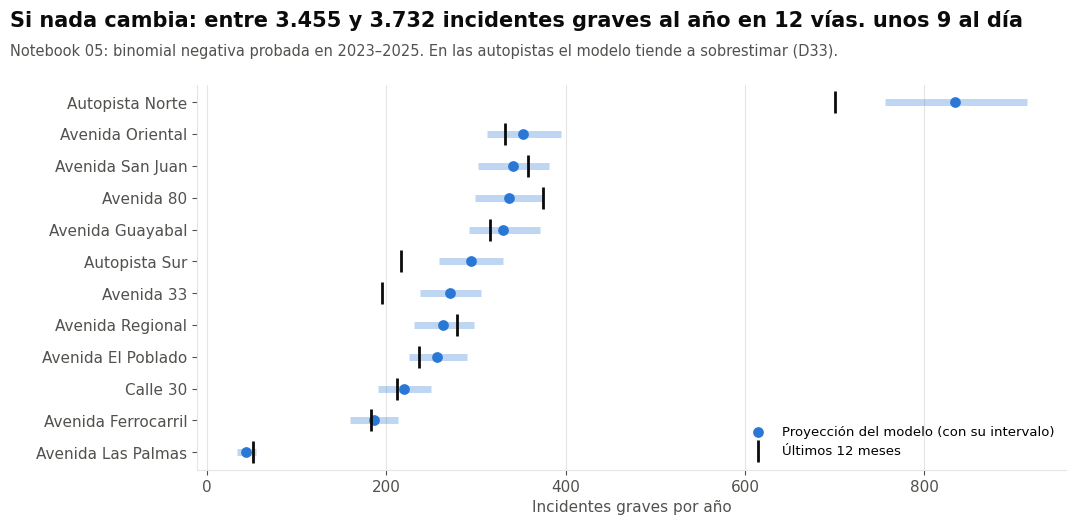

In [16]:
fig = G.no_actuar(H.proyeccion(), NOMBRE); guardar(fig, "10_no_actuar")

- En las 3 vías rápidas mueren unas **24 personas al año** y hay unos **1.419 incidentes graves**: esa es la línea base de las vidas salvadas.
- La Autopista Norte, con 700 a 835 incidentes graves al año, duplica a cualquier otro corredor.

> **Cómo lo sabemos:** pusimos a competir 4 modelos (dos que repiten el pasado, una binomial negativa y XGBoost), entrenados hasta 2022 y probados en 2023–2025, años que no vieron. La regla para elegir se fijó antes de ver los resultados. Ganó el modelo más simple que se puede explicar: la binomial negativa superó a XGBoost (error 2,36 contra 4,33). Contamos también que sobrestimó 2023–2025 en un 10%, en parte porque el registro cambió en 2024 (paso 12).

→ *¿Cuánto cambiaría eso con las medidas de Bogotá y Malasia?*

### 11 · Segundos contra vidas
**Un carril de motos en las 3 vías rápidas salvaría unas 4 vidas al año sin costar segundos. Un tope de 50 km/h en la Regional salvaría 1 vida al año por 57 segundos por viaje. Juntas, las dos medidas evitarían una de cada cuatro muertes.**

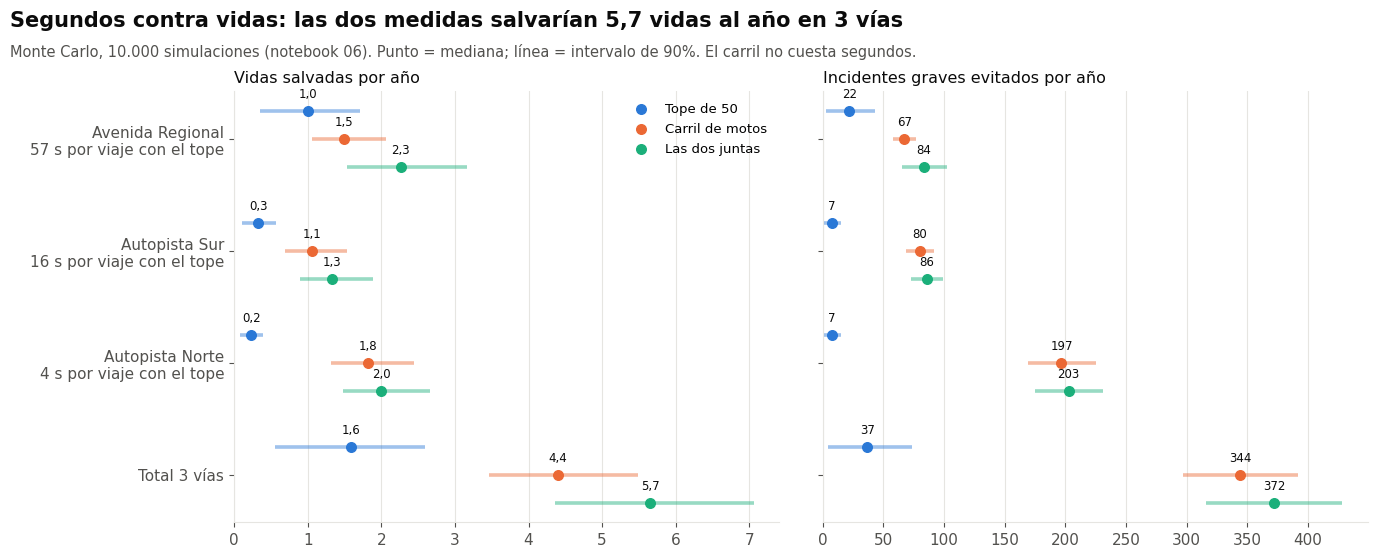

In [17]:
comp = H.comparacion()
fig = G.segundos_contra_vidas(comp); guardar(fig, "11_segundos_contra_vidas")

- **Tope de 50 con control permanente:** 1,6 vidas al año en las 3 vías (entre 0,6 y 2,6) y 37 incidentes graves. Casi todo en la Regional. En la Autopista Norte casi no cambia nada, porque allí poca gente pasa de 50.
- **Carril de motos:** 4,4 vidas al año (entre 3,5 y 5,5) y 344 incidentes graves. Donde más rinde es la Autopista Norte, justo donde el tope no sirve.
- **El orden no depende del supuesto más dudoso:** el carril salva más que el tope incluso en el mejor caso para el tope (literatura clásica: 3,3 vidas al año).
- **Prueba de sensatez:** en la Regional, el −22% a −37% de Bogotá cae en la parte alta de nuestro rango (6% a 25% de sus muertes).

> **Cómo lo sabemos:** repetimos el cálculo 10.000 veces. En cada vuelta sorteamos lo que no sabemos con exactitud: cuánto pesa la velocidad, cuántos conductores cumplen el tope, cuánto reduce el carril y cuántos muertos hay en un año. Nos quedamos con el rango.

> **Cuidado:** el intervalo del carril es estrecho porque el rango de Malasia lo es, no porque el resultado sea seguro. Descansa en un solo estudio de 1995, sin grupo de control. El carril no cuesta segundos, pero sí espacio e infraestructura, que estos datos no permiten medir.

<details><summary>Nota técnica: qué entra al Monte Carlo</summary>

Exponente entre el piso de Medellín y Elvik urbano; letalidad entre 0 y 2; velocidad registro por registro; factor de noche del SIMM; cumplimiento del 85% al 100% (supuesto nuestro, con control permanente); muertos del Distrito e incidentes graves del ITM por vía; % de víctimas en moto con su incertidumbre; reducción de Malasia entre 25% y 34%. Detalle en el anexo 06.
</details>

→ *Y si se aplican, ¿cómo sabría Medellín si funcionaron?*

### 12 · Para saber si funciona, hay que poder medirlo
**Bogotá supo que su medida salvó vidas porque midió antes y después. Con los datos abiertos de hoy, Medellín no podría hacerlo.**

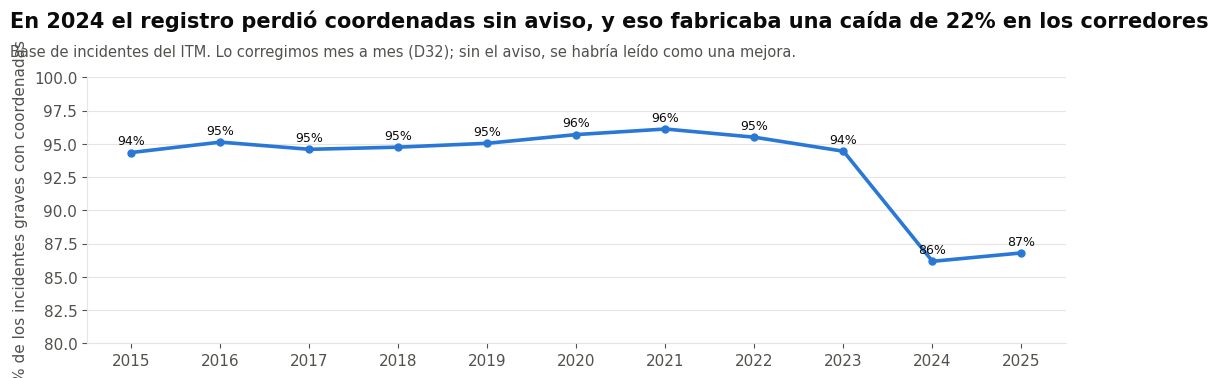

In [18]:
fig = G.cobertura(H.cobertura_coordenadas(inc)); guardar(fig, "12_cobertura")

| Mejora para MEData | Qué encontramos | Qué permitiría |
|---|---|---|
| **Velocidad y volumen continuos, las 24 horas** | La velocidad se publica en pedazos: 2017–2020 solo de día, y la de 24 horas son dos meses de pandemia | Medir la velocidad antes y después de un tope |
| **Contar las motos aparte** | En el SIMM, carros y motos vienen en la misma categoría | Saber cuántas motos usan cada corredor |
| **Mantener actualizado el archivo de víctimas** | Termina en septiembre de 2021, justo antes de que las muertes suban | Saber quién muere hoy |
| **Un identificador común y la ubicación de cada tramo** | Las bases no se pueden unir; los tramos de velocidad no traen coordenadas | Seguir un mismo corredor en todas las fuentes |
| **Avisar cuando cambia el registro** | En 2024 se perdieron coordenadas sin aviso (gráfica) | Que una caída en los datos no se confunda con una mejora |

*MEData hizo posible este análisis; con estos cambios, haría posible evaluarlo.*

→ *Queda un riesgo que ni el tope ni el carril explican del todo.*

---
### 13 · Lo que la velocidad no resuelve: la madrugada
**De noche no se va más rápido, pero cada choque mata entre 2 y 4,5 veces más.**

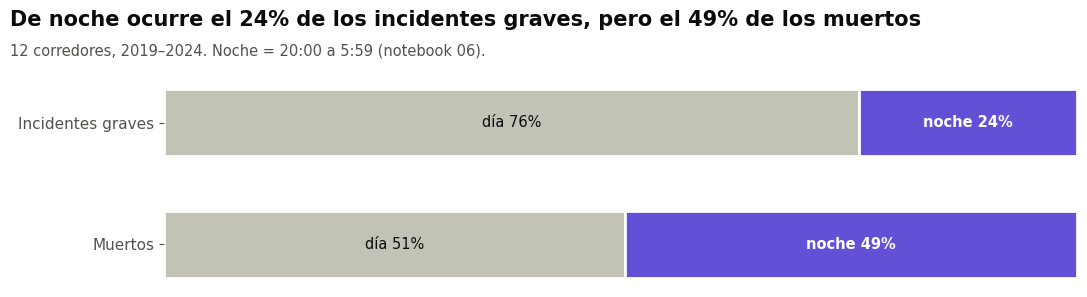

In [19]:
fig = G.dia_noche(H.dia_noche_corredores()); guardar(fig, "13_dia_noche")

- La velocidad no explica la diferencia: de noche es la misma que de día. La madrugada triplica el riesgo de morir aun comparando víctimas del mismo perfil (paso 4).
- El tope sí ayuda de noche, porque el exceso sobre 50 no se apaga. Pero la mayor parte de ese riesgo pide otras medidas: control de alcohol, iluminación y respuesta médica.
- Reconocerlo hace la propuesta más honesta.

→ *Con todo esto, esta es la propuesta.*

---
## Cierre · Lo que proponemos
**Dos problemas, dos medidas, en solo 3 vías: la Regional tiene un problema de velocidad; las autopistas, un problema de motos.**

| Orden | Dónde | Medida principal | Vidas por año con las dos medidas | Incidentes graves evitados por año | Costo en tiempo |
|---|---|---|---|---|---|
| 1 | Regional | Tope de 50 km/h con control permanente | 2,3 (1,5 – 3,2) | 84 | 57 s por viaje |
| 2 | Autopista Norte | Carril exclusivo de motos | 2,0 (1,5 – 2,7) | 203 | 4 s por viaje |
| 3 | Autopista Sur | Carril exclusivo de motos | 1,3 (0,9 – 1,9) | 86 | 16 s por viaje |
| | **Las 3 vías** | **Tope de 50 + carril de motos** | **5,7 (4,4 – 7,1)** | **372** | |

En cada vía se aplican las dos medidas; la "medida principal" es la que más pesa allí.

### No son solo vidas: también se evitan accidentes

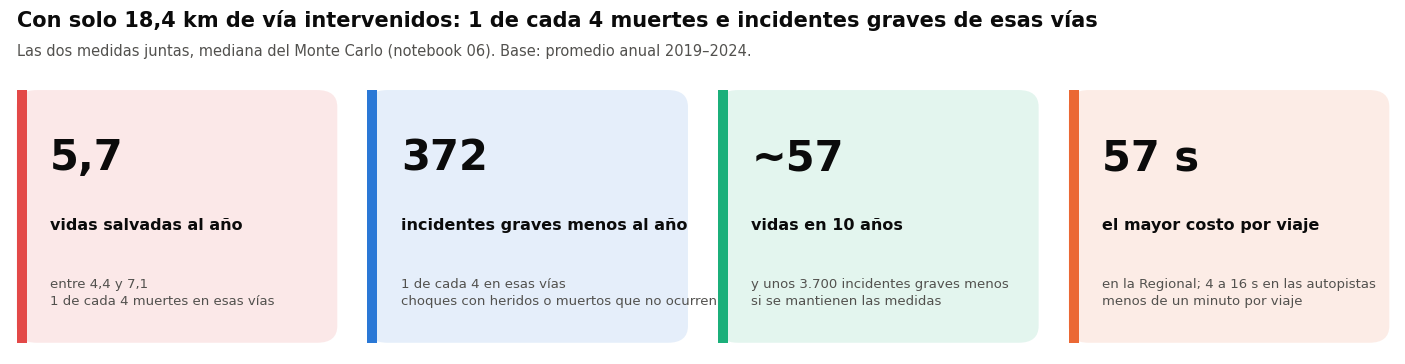

In [20]:
evita = H.lo_que_se_evita(inc, mor, RAPIDAS)
fig = G.lo_que_cambia(evita, comp, H.largo_vias(RAPIDAS)); guardar(fig, "14_lo_que_cambia")

- **Cada año habría unos 372 choques con heridos o muertos menos** y unas 6 personas no morirían, en solo 3 vías. En 10 años serían unas 57 vidas.
- **No se compromete la movilidad:** el mayor costo es menos de un minuto por viaje en la Regional, y unos segundos en las autopistas. En la congestión, el tope no cuesta nada.
- **Por qué empezar por aquí:** estas 3 vías concentran casi la mitad de los muertos de los 12 corredores principales. Es donde cada intervención rinde más.
- **En toda la ciudad** equivale al 2% de las muertes y al 1% de los incidentes graves. Lo decimos tal cual: es un primer paso, en el lugar donde más rinde, y las mismas medidas se pueden evaluar después en otras vías.

> **Cuando se trata de vidas, ningún aporte es pequeño.** Cada una de esas 6 personas al año tiene nombre, familia y una vida por delante. Y salvarlas cuesta segundos, no la movilidad de la ciudad.

### Qué proponemos, en concreto
1. **Regional: tope de 50 km/h con control permanente** (cámaras de fotodetección, o puestos de control con multas, como hizo Bogotá en 2018). Sin control, el efecto sería mucho menor.
2. **Autopista Norte, Autopista Sur y Regional: carril exclusivo de motos**, empezando por la Autopista Norte, donde más rinde.
3. **Medir antes y después:** con las 5 mejoras a los datos del paso 12, para saber si funcionó.
4. **Paso siguiente:** un límite variable con avisos, que en autopistas de Estados Unidos redujo los choques entre 29% y 34%.

**A quién protege cada medida:** el tope, sobre todo a los más vulnerables (peatones, ciclistas y mayores); el carril, por volumen: en las 3 vías, más del 80% de las víctimas va en moto.

**Lo que no proponemos:** un tope de 50 en las arterias, porque allí la congestión ya obliga a ir despacio.

### Limitaciones
- **El tope supone control permanente:** el cumplimiento se sorteó entre 85% y 100%, un supuesto nuestro.
- **El carril descansa en un solo estudio** (Malasia, 1995, sin grupo de control). Su intervalo es estrecho porque el estudio lo es, no porque el resultado sea seguro. Y aplicado a las muertes supone que bajan igual que los accidentes.
- **El efecto de la velocidad se tomó con un rango conservador**, porque la evidencia de Medellín es débil (pasos 8 y 9).
- **Los segundos son por viaje,** no horas totales de la ciudad, y solo para quien cumple el tope.
- **Los periodos de las fuentes no coinciden:** velocidades de 2017–2019, muertos de 2019–2024 y víctimas de 2014–2021.
- **No estimamos** el costo del carril en espacio e infraestructura, ni si el tráfico se desvía a otras vías.

*Medellín no tiene que inventar nada: tiene que decidir dónde aplicar lo que ya funcionó. Estos datos dicen dónde empezar.*

---
## Fuentes, decisiones y uso de IA
- **Datos:** las 7 fuentes de la Parte 0, con sus URLs en `src/fuentes.py`.
- **Referentes:** `docs/referentes.md` (Bogotá, Malasia, Elvik, Nilsson, FHWA), verificados en su fuente.
- **Decisiones del análisis:** `docs/DECISIONES.md` (D1 a D39), cada una con su razón.
- **Anexos:** `notebooks/01` a `06`, con todo el detalle técnico.
- **Uso de IA:** documentado en `docs/` por cada integrante.